[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[![VGI](assets/vgi-logo.png)](https://query.farm/vgi/)

# Choose the denominator before drawing the chart

Which region has the highest failure rate? An average of weekly percentages answers a different question from failures divided by all requests. We make both calculations in SQL, then ask the **real Java chart worker** to render a time series and a grouped comparison as PNG BLOBs. Python displays those returned images; it does not redraw the analytical charts.

**All observations are synthetic.** Twelve rows describe four invented weeks of requests and failures in Aster, Briar and Cedar. Every request belongs to one region-week cell and is counted once. This example concerns aggregation choices, not a real service’s reliability.

## Choose a reporting horizon

`WEEKS` is an integer from 2 to 4; default 4. It includes weeks 1 through `WEEKS`, inclusive, from the same fixed fixture. The final experiment uses only the first two weeks. Restart and run all after changing the parameter.

In [1]:
WEEKS = 4  # inclusive synthetic reporting horizon; integer 2–4

In [2]:
import haybarn
from IPython.display import display

from notebook_support import prose, show_worker_png, theme

if type(WEEKS) is not int or not 2 <= WEEKS <= 4:
    raise ValueError("WEEKS must be an integer from 2 to 4.")
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-chart/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-chart/notebooks/pyproject.toml.

## Attach the published JAR

The literal launcher downloads release v0.4.0, checks the pinned SHA256 and runs it with Java 21 or newer. The JAR includes its dependencies and runs headlessly. Nothing is built from this checkout. The companion caches the verified artifact and sends setup output to stderr, leaving stdout for VGI.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'chart' (TYPE vgi,
    LOCATION 'uv run --no-project --python 3.13 release_jar.py Query-farm/vgi-chart v0.4.0 vgi-chart-v0.4.0.jar 532df4080167ff55381fa282682abeb149f4b7e7a9e72aeaf3ea68878e45f6c7'
);

,Success


## Build and inspect the weekly observations

The table grain is one region per week. Request volume changes over time, particularly in Briar. Compute each weekly percentage from its own numerator and positive denominator before plotting. No missing value is replaced with zero.

In [4]:
%%sql
CREATE TABLE observations AS
SELECT * FROM (VALUES
    (1, 'Aster', 1000, 20), (2, 'Aster', 1200, 36),
    (3, 'Aster', 800, 64),  (4, 'Aster', 1400, 112),
    (1, 'Briar', 100, 10),  (2, 'Briar', 100, 10),
    (3, 'Briar', 500, 15),  (4, 'Briar', 500, 15),
    (1, 'Cedar', 400, 16),  (2, 'Cedar', 500, 20),
    (3, 'Cedar', 600, 24),  (4, 'Cedar', 700, 28)
) AS t(week, region, requests, failures);

CREATE TABLE weekly AS
SELECT *, 100.0 * failures / requests AS failure_pct
FROM observations WHERE week BETWEEN 1 AND {{WEEKS}};

SELECT week, region, requests, failures, failure_pct
FROM weekly ORDER BY region, week;

,week,region,requests,failures,failure_pct
0,1,Aster,1000,20,2.0
1,2,Aster,1200,36,3.0
2,3,Aster,800,64,8.0
3,4,Aster,1400,112,8.0
4,1,Briar,100,10,10.0
5,2,Briar,100,10,10.0
6,3,Briar,500,15,3.0
7,4,Briar,500,15,3.0
8,1,Cedar,400,16,4.0
9,2,Cedar,500,20,4.0


## Render the weekly pattern through SQL

The chart function consumes a relation and returns PNG bytes. Column names become axis labels; here they include the percentage unit. Categorical week labels avoid implying fractional observation weeks. The ordered input fixes a consistent region legend. Materialize the render once, then read its local BLOB for display. Both images in this notebook come from the worker.

The worker can emit a chart-so-far for each input batch. This deliberately small relation is validated to return **one** PNG row; the display helper refuses multiple images rather than guessing which partial chart is complete. It also verifies the PNG format and requested 1100 × 640 pixel dimensions.

In [5]:
%%sql
CREATE TABLE weekly_png AS
SELECT png FROM chart.main.chart_line(
    (SELECT 'Week ' || CAST(week AS VARCHAR) AS "Week", failure_pct AS "Failure rate (%)", region AS "Region"
     FROM weekly ORDER BY region, week),
    x := 'Week', y := 'Failure rate (%)', series := 'Region',
    title := 'Weekly failure rates | synthetic weeks 1-{{WEEKS}}', width := 1100, height := 640
);

,Count


In [6]:
%%sql line_blob <<
SELECT png FROM weekly_png;

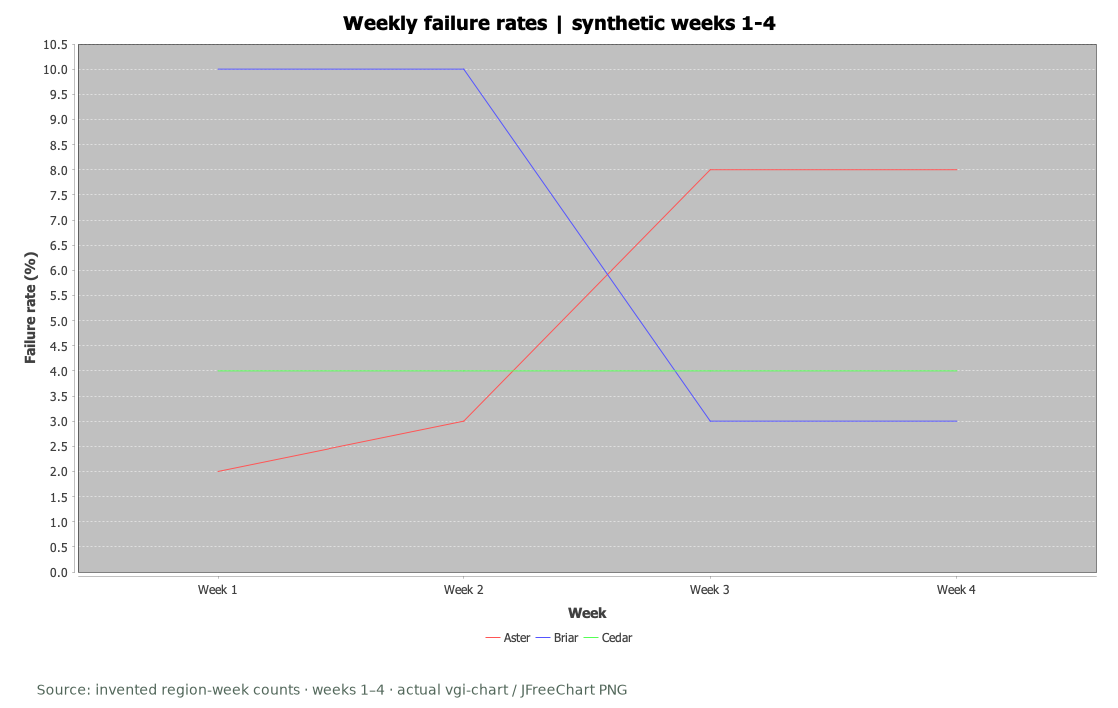

{'png_bytes': 37088, 'width_px': 1100, 'height_px': 640, 'png_rows': 1}

In [7]:
line_details = show_worker_png(
    line_blob,
    f"weekly-rates-{WEEKS}.png",
    f"Source: invented region-week counts · weeks 1–{WEEKS} · actual vgi-chart / JFreeChart PNG",
)
display(line_details)

## Two valid summaries, two different weights

The **average weekly rate** gives each week equal weight: it describes the mean percentage of a uniformly selected week. The **pooled request rate** gives each request equal weight: total failures divided by total requests. It is also the request-weighted average of weekly percentages. These are different estimands; the right one depends on whether the question is about weeks or requests.

Aggregate explicitly before passing data to the renderer. A bar chart expects one value per category-series pair; duplicate pairs in this worker replace earlier values rather than summing them.

In [8]:
%%sql
CREATE TABLE regional_rates AS
SELECT region, count(*) AS weeks_observed, sum(requests) AS requests,
       sum(failures) AS failures,
       avg(failure_pct) AS average_week_pct,
       100.0 * sum(failures) / sum(requests) AS pooled_request_pct,
       sum(failure_pct * requests) / sum(requests) AS weighted_week_pct
FROM weekly GROUP BY region;

CREATE TABLE comparison AS
SELECT region, 'Average week' AS weighting, average_week_pct AS failure_pct FROM regional_rates
UNION ALL
SELECT region, 'Pooled requests' AS weighting, pooled_request_pct AS failure_pct FROM regional_rates;

,Count


In [9]:
%%sql rates <<
SELECT region, weeks_observed, requests, failures, average_week_pct, pooled_request_pct,
       average_week_pct - pooled_request_pct AS averaging_gap_percentage_points
FROM regional_rates ORDER BY region;

In [10]:
display(rates)

,region,weeks_observed,requests,failures,average_week_pct,pooled_request_pct,averaging_gap_percentage_points
0,Aster,4,4400.0,232.0,5.25,5.272727,-0.022727
1,Briar,4,1200.0,50.0,6.50,4.166667,2.333333
2,Cedar,4,2200.0,88.0,4.00,4.000000,0.000000


In [11]:
weekly_leader = rates.loc[rates.average_week_pct.idxmax()]
pooled_leader = rates.loc[rates.pooled_request_pct.idxmax()]
prose(
    f"Across synthetic weeks **1–{WEEKS}**, **{weekly_leader.region}** has the highest average weekly rate "
    f"at **{weekly_leader.average_week_pct:.2f}%**. **{pooled_leader.region}** has the highest pooled "
    f"request rate at **{pooled_leader.pooled_request_pct:.2f}%**. "
    f"The pooled calculation covers **{int(rates.requests.sum()):,} requests** and "
    f"**{int(rates.failures.sum()):,} failures** across the three regions."
)
briar = rates.set_index("region").loc["Briar"]
prose(
    f"For Briar, averaging weekly percentages gives **{briar.average_week_pct:.2f}%**, while "
    f"pooling requests gives **{briar.pooled_request_pct:.2f}%**: a gap of "
    f"**{briar.averaging_gap_percentage_points:+.2f} percentage points**. "
    "Inspect the weekly counts to see which weeks receive more weight in the pooled result."
)

Across synthetic weeks **1–4**, **Briar** has the highest average weekly rate at **6.50%**. **Aster** has the highest pooled request rate at **5.27%**. The pooled calculation covers **7,800 requests** and **370 failures** across the three regions.

For Briar, averaging weekly percentages gives **6.50%**, while pooling requests gives **4.17%**: a gap of **+2.33 percentage points**. Inspect the weekly counts to see which weeks receive more weight in the pooled result.

## Render the comparison from the aggregated relation

The category identifies the weighting rule, the series identifies the region and the value is a percentage. The region order matches the line chart so its colors and labels stay consistent. This chart visualizes the SQL table above; the renderer does not choose the denominator.

In [12]:
%%sql
CREATE TABLE comparison_png AS
SELECT png FROM chart.main.chart_bar(
    (SELECT weighting AS "Weighting rule", failure_pct AS "Failure rate (%)", region AS "Region"
     FROM comparison ORDER BY region, weighting),
    category := 'Weighting rule', value := 'Failure rate (%)', series := 'Region',
    title := 'The denominator changes the comparison | synthetic weeks 1-{{WEEKS}}',
    width := 1100, height := 640
);

,Count


In [13]:
%%sql bar_blob <<
SELECT png FROM comparison_png;

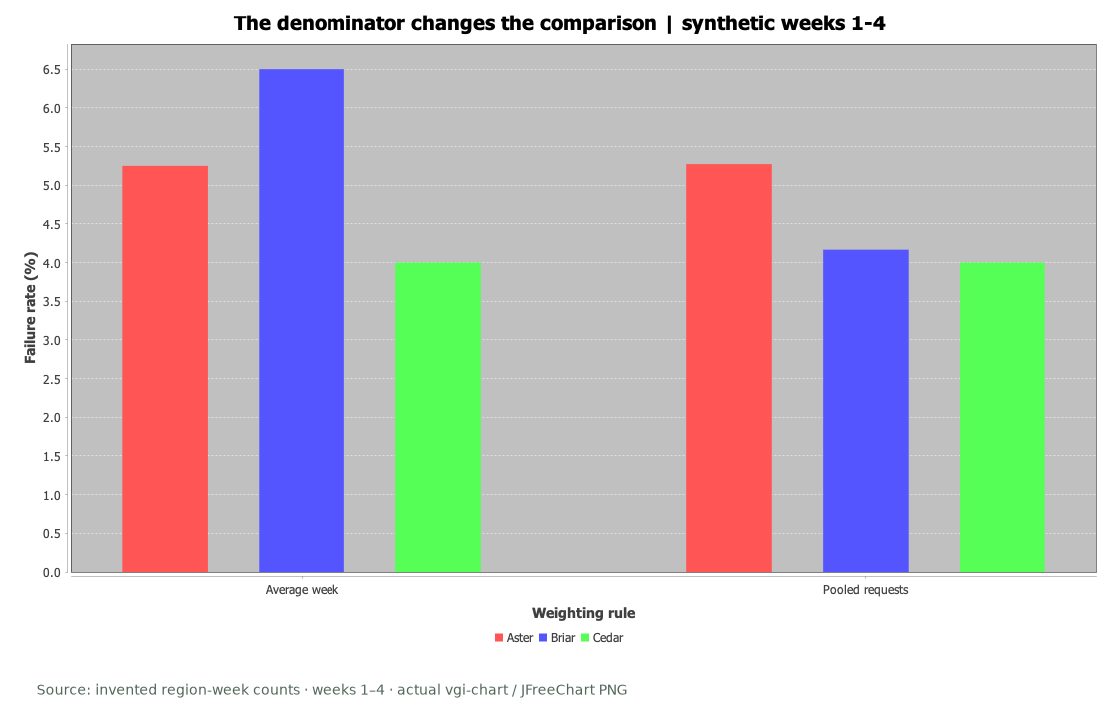

{'png_bytes': 33847, 'width_px': 1100, 'height_px': 640, 'png_rows': 1}

In [14]:
bar_details = show_worker_png(
    bar_blob,
    f"weighting-comparison-{WEEKS}.png",
    f"Source: invented region-week counts · weeks 1–{WEEKS} · actual vgi-chart / JFreeChart PNG",
)
display(bar_details)

## Verify the denominators and rendered artifacts

Check the input grain, numerator bounds, equivalence of the two request-weighted formulas and one-row image outputs. PNG bytes need not be identical across operating systems or Java font environments; format, dimensions and analytical values are the useful invariants.

In [15]:
%%sql checks <<
SELECT 'one observation per region-week' AS check_name,
       count(*) = count(DISTINCT (region, week)) AS passed FROM weekly
UNION ALL
SELECT 'positive denominators and bounded failures', bool_and(requests > 0 AND failures BETWEEN 0 AND requests) FROM weekly
UNION ALL
SELECT 'pooled rate equals request-weighted weekly rate',
       max(abs(pooled_request_pct - weighted_week_pct)) < 1e-10 FROM regional_rates
UNION ALL
SELECT 'unique chart category-series pairs', count(*) = count(DISTINCT (weighting, region)) FROM comparison
UNION ALL
SELECT 'one valid line PNG', count(*) = 1 AND bool_and(png[1:4] = '\x89PNG'::BLOB AND octet_length(png) > 100) FROM weekly_png
UNION ALL
SELECT 'one valid bar PNG', count(*) = 1 AND bool_and(png[1:4] = '\x89PNG'::BLOB AND octet_length(png) > 100) FROM comparison_png;

In [16]:
display(checks)
assert checks.passed.fillna(False).all(), "A grain, denominator or PNG invariant failed."

,check_name,passed
0,one observation per region-week,True
1,positive denominators and bounded failures,True
2,pooled rate equals request-weighted weekly rate,True
3,unique chart category-series pairs,True
4,one valid line PNG,True
5,one valid bar PNG,True


## Experiment: shorten the horizon

Change only **`WEEKS` from 4 to 2**. Predict that Briar’s two summaries become equal because its first two weeks have equal request volumes and equal failure rates. Predict which region leads each ranking after removing the later weeks, then run all and compare the rate table and both returned charts.

This changes the reporting population; it does not demonstrate that aggregation causes a service to improve or deteriorate. Rates for a different period answer a different question. Reset **`WEEKS = 4`**. The README shows how to save the experiment separately. Raw worker PNGs and the displayed copies with source footers are saved under the ignored `validation/` folder.

In [17]:
connection.close()

[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)